# idk what happened

In [1]:
import torch
print(torch.__version__)

2.5.1+cu121


In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam
from captum.attr import visualization as viz

# Ensure reproducibility
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


/home/akshay/miniconda3/envs/pytorch_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Pipeline Initialization

In [5]:
def load_and_preprocess_data(filepath='chestxray_binary_64.npz', batch_size=128):
    data = np.load(filepath)
    print("Keys inside the npz file:", data.files)

    
    # Extract splits using the correct keys from your npz file
    X_train, y_train = data['train_images'], data['train_labels']
    X_val, y_val = data['val_images'], data['val_labels']
    X_test, y_test = data['test_images'], data['test_labels']
    
    # Scale to [0, 1]
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    
    # Normalize using train mean and std
    train_mean = np.mean(X_train)
    train_std = np.std(X_train)
    
    X_train = (X_train - train_mean) / train_std
    X_val = (X_val - train_mean) / train_std
    X_test = (X_test - train_mean) / train_std
    
    # Convert to PyTorch tensors (N, C, H, W)
    X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
    y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
    X_val_t = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
    y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
    X_test_t = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)
    y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)
    
    # Create DataLoaders
    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)
    
    return train_loader, val_loader, test_loader, X_test_t, y_test_t

# Run the function
train_loader, val_loader, test_loader, X_test_t, y_test_t = load_and_preprocess_data()
print("Data loaded successfully! Shapes:", X_test_t.shape)

Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Data loaded successfully! Shapes: torch.Size([624, 1, 64, 64])


## Traiing Config

In [6]:
class EarlyStopping:
    def __init__(self, patience=4, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

def train_model(model, train_loader, val_loader, lr, max_epochs=20):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    early_stopping = EarlyStopping()
    
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
            
        model.eval()
        val_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                preds = torch.round(torch.sigmoid(outputs))
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        train_loss /= len(train_loader.dataset)
        val_loss /= len(val_loader.dataset)
        val_acc = correct / total
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        early_stopping(val_loss)
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
            
    return history

## Convolution Base

In [7]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c, kernel_size, stride=1):
        super().__init__()
        # PyTorch calculates SAME padding for odd kernels as kernel_size // 2
        padding = kernel_size // 2 if stride == 1 else (kernel_size // 2)
        self.conv = nn.Conv2d(in_c, out_c, kernel_size, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_c)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))

## Alex-Net Like

In [8]:
class B1_AlexNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 16, 5),
            nn.MaxPool2d(2, 2),
            ConvBlock(16, 32, 5),
            nn.MaxPool2d(2, 2),
            ConvBlock(32, 64, 3),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64, bias=True),
            nn.Dropout(0.5),
            nn.ReLU(),
            nn.Linear(64, 32, bias=True),
            nn.Dropout(0.5),
            nn.ReLU(),
            nn.Linear(32, 1, bias=True)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

## B1 Hyperparameter Search

Training B1 with LR: 1e-05
Training B1 with LR: 0.0001
Training B1 with LR: 0.001
Early stopping triggered at epoch 14
Training B1 with LR: 0.01
Early stopping triggered at epoch 10
Training B1 with LR: 0.1
Early stopping triggered at epoch 10
Plot saved successfully to images/learning_rate_comparison.png


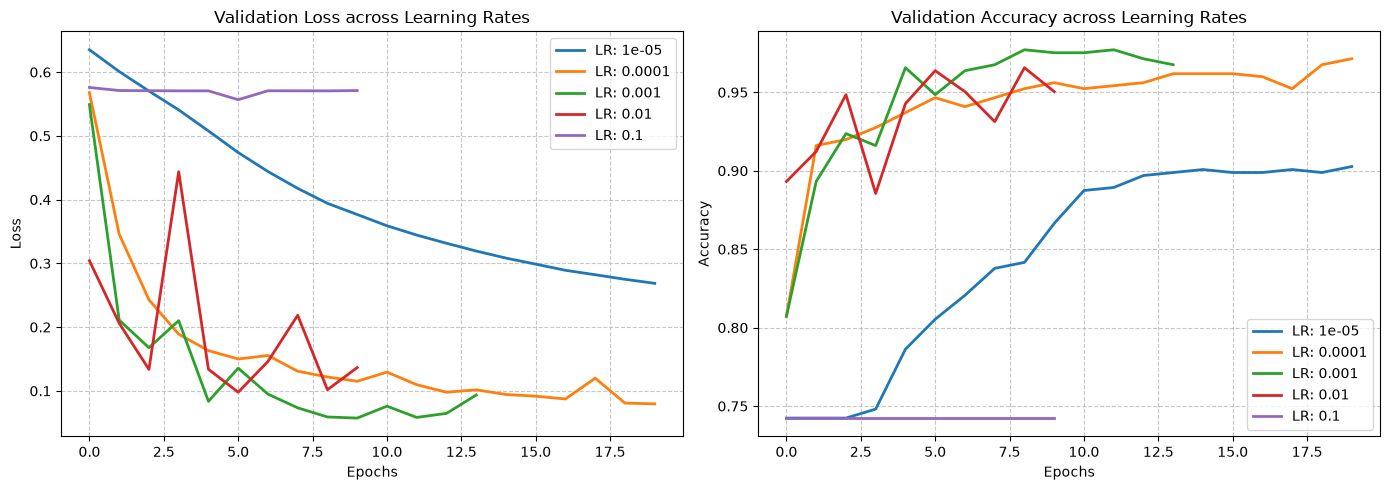

Best LR for B1: 0.001


In [9]:
import os
import matplotlib.pyplot as plt

lrs = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
b1_results = {}

for lr in lrs:
    print(f"Training B1 with LR: {lr}")
    model_b1 = B1_AlexNet().to(device)
    history = train_model(model_b1, train_loader, val_loader, lr)
    b1_results[lr] = history

# --- Plotting and Saving Both Loss and Accuracy ---
# Ensure the 'images' directory exists
os.makedirs('images', exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr, history in b1_results.items():
    # Plot Validation Loss (Left Subplot)
    axes[0].plot(history['val_loss'], label=f'LR: {lr}', linewidth=2)
    # Plot Validation Accuracy (Right Subplot)
    axes[1].plot(history['val_acc'], label=f'LR: {lr}', linewidth=2)

# Format Validation Loss plot
axes[0].set_title('Validation Loss across Learning Rates')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

# Format Validation Accuracy plot
axes[1].set_title('Validation Accuracy across Learning Rates')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()

# Save the figure to the local 'images/' folder
output_path = os.path.join('images', 'learning_rate_comparison.png')
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Plot saved successfully to {output_path}")

plt.show() # Optional: keeps the inline display too
# --------------------------------------------------

# Determine best LR based on highest validation accuracy
best_lr_b1 = max(b1_results, key=lambda k: max(b1_results[k]['val_acc']))
print(f"Best LR for B1: {best_lr_b1}")

# BCG Like Architecture

In [10]:
class B2_VGG(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 8, 3),
            ConvBlock(8, 8, 3),
            nn.MaxPool2d(2, 2),
            ConvBlock(8, 16, 3),
            ConvBlock(16, 16, 3),
            nn.MaxPool2d(2, 2),
            ConvBlock(16, 32, 3),
            ConvBlock(32, 32, 3),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32, 1, bias=True)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# B2 Hyperparameter Search

Training B2 with Batch Size: 16
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Training B2 with Batch Size: 32
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 17
Training B2 with Batch Size: 64
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 13
Training B2 with Batch Size: 128
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 19
Training B2 with Batch Size: 256
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 15
Plot saved successfully to images/batch_size_comparison.png


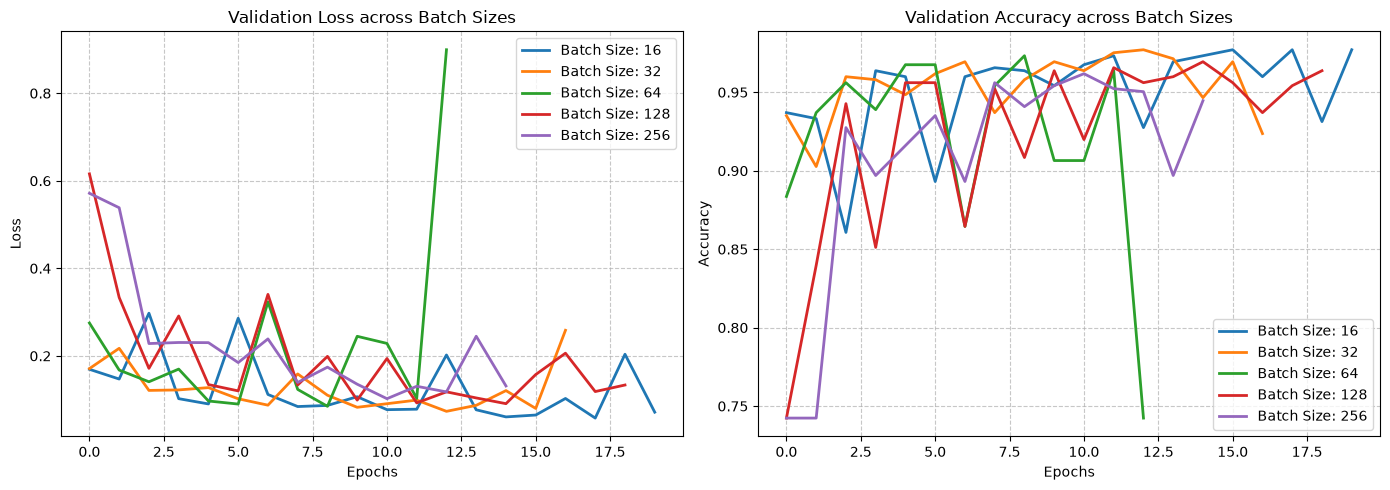

Best Batch Size for B2: 16


In [11]:
import os
import matplotlib.pyplot as plt

batch_sizes = [16, 32, 64, 128, 256]
b2_results = {}

for bs in batch_sizes:
    print(f"Training B2 with Batch Size: {bs}")
    # Recreate dataloaders for specific batch size
    train_loader_bs, val_loader_bs, _, _, _ = load_and_preprocess_data(batch_size=bs)
    
    model_b2 = B2_VGG().to(device)
    history = train_model(model_b2, train_loader_bs, val_loader_bs, lr=best_lr_b1)
    b2_results[bs] = history

# --- Plotting and Saving Both Loss and Accuracy for Batch Sizes ---
os.makedirs('images', exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for bs, history in b2_results.items():
    # Plot Validation Loss (Left Subplot)
    axes[0].plot(history['val_loss'], label=f'Batch Size: {bs}', linewidth=2)
    # Plot Validation Accuracy (Right Subplot)
    axes[1].plot(history['val_acc'], label=f'Batch Size: {bs}', linewidth=2)

# Format Validation Loss plot
axes[0].set_title('Validation Loss across Batch Sizes')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

# Format Validation Accuracy plot
axes[1].set_title('Validation Accuracy across Batch Sizes')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()

# Save the figure to the local 'images/' folder
output_path = os.path.join('images', 'batch_size_comparison.png')
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Plot saved successfully to {output_path}")

plt.show()
# -----------------------------------------------------------------

best_bs_b2 = max(b2_results, key=lambda k: max(b2_results[k]['val_acc']))
print(f"Best Batch Size for B2: {best_bs_b2}")

### Retrying - To reduce instability

Training VGG with Batch Size: 16 at LR: 0.0001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Training VGG with Batch Size: 32 at LR: 0.0001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Training VGG with Batch Size: 64 at LR: 0.0001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Training VGG with Batch Size: 128 at LR: 0.0001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Training VGG with Batch Size: 256 at LR: 0.0001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Plot saved to images/vgg_batch_size_comparison.png


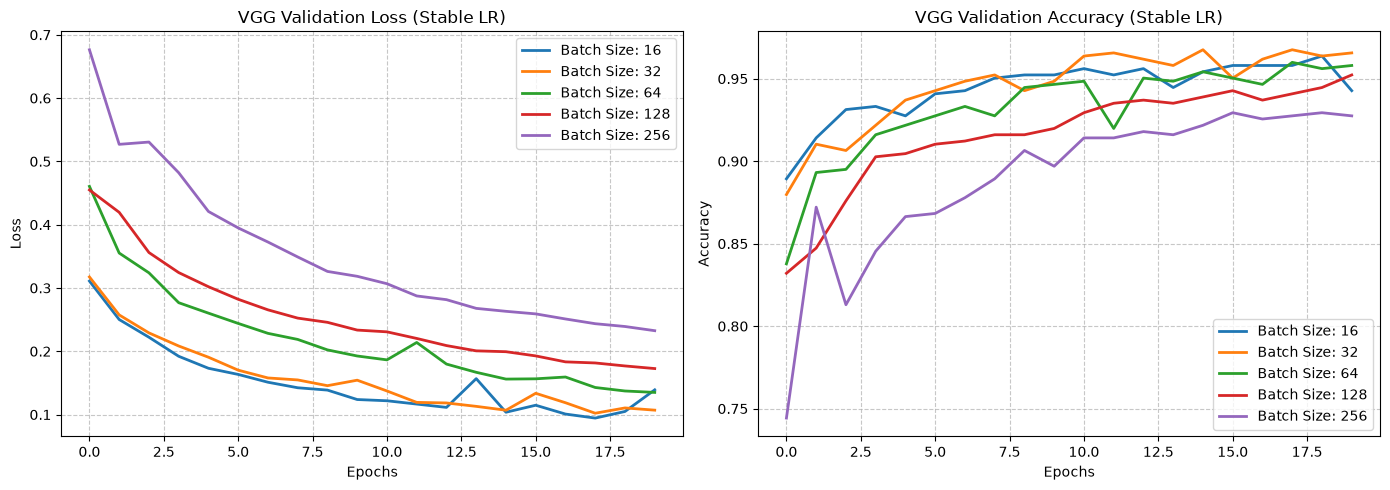

Best Batch Size for VGG: 32


In [13]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

def train_vgg_model(model, train_loader, val_loader, lr, epochs=20):
    criterion = nn.BCEWithLogitsLoss()
    # Add weight decay here to stabilize VGG's deep weights
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # Scheduler to lower LR if validation loss plateaus
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
    
    history = {'val_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            
            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
            
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                
                preds = (torch.sigmoid(outputs) > 0.5).float()
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        
        scheduler.step(epoch_val_loss)
        
    return history

# --- VGG Batch Size Experiment with Safer LR ---
batch_sizes = [16, 32, 64, 128, 256]
b2_results = {}

# Use a safer, lower learning rate specifically for VGG (e.g., 1e-4)
vgg_lr = 1e-4 

for bs in batch_sizes:
    print(f"Training VGG with Batch Size: {bs} at LR: {vgg_lr}")
    train_loader_bs, val_loader_bs, _, _, _ = load_and_preprocess_data(batch_size=bs)
    
    model_b2 = B2_VGG().to(device)
    history = train_vgg_model(model_b2, train_loader_bs, val_loader_bs, lr=vgg_lr)
    b2_results[bs] = history

# --- Plotting ---
os.makedirs('images', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for bs, history in b2_results.items():
    axes[0].plot(history['val_loss'], label=f'Batch Size: {bs}', linewidth=2)
    axes[1].plot(history['val_acc'], label=f'Batch Size: {bs}', linewidth=2)

axes[0].set_title('VGG Validation Loss (Stable LR)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

axes[1].set_title('VGG Validation Accuracy (Stable LR)')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
output_path = os.path.join('images', 'vgg_batch_size_comparison.png')
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Plot saved to {output_path}")
plt.show()

best_bs_b2 = max(b2_results, key=lambda k: max(b2_results[k]['val_acc']))
print(f"Best Batch Size for VGG: {best_bs_b2}")

# B3 - ResNet Like Architecture

In [14]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = ConvBlock(in_c, out_c, 3, stride=stride)
        # Note: BatchNorm and ReLU are inside ConvBlock
        self.conv2 = nn.Conv2d(out_c, out_c, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_c)
            )
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out) # ReLU applied after residual addition

class B3_ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.prep = nn.Sequential(
            ConvBlock(1, 16, 3),
            nn.MaxPool2d(2, 2)
        )
        self.layer1 = ResBlock(16, 16, stride=1)
        self.layer2 = ResBlock(16, 32, stride=2)
        self.layer3 = ResBlock(32, 64, stride=2)
        
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, 1, bias=True)

    def forward(self, x):
        x = self.prep(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

#### Function to plain a model - Wihtout any modifitcations/specifications

In [18]:
!pip install torchinfo scikit-learn

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 9.8 MB/s  0:00:00 eta 0:00:01m
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 9.4 MB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [scikit-learn] [scikit-learn]


--- Training B3 ResNet (Plain Training) ---
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Epoch [1/20] - Val Loss: 0.1817 - Val Acc: 0.9294
Epoch [2/20] - Val Loss: 0.2747 - Val Acc: 0.8893
Epoch [3/20] - Val Loss: 0.1250 - Val Acc: 0.9542
Epoch [4/20] - Val Loss: 0.0732 - Val Acc: 0.9752
Epoch [5/20] - Val Loss: 0.3657 - Val Acc: 0.8683
Epoch [6/20] - Val Loss: 0.1078 - Val Acc: 0.9637
Epoch [7/20] - Val Loss: 0.1370 - Val Acc: 0.9466
Epoch [8/20] - Val Loss: 0.1168 - Val Acc: 0.9523
Epoch [9/20] - Val Loss: 0.1008 - Val Acc: 0.9637
Epoch [10/20] - Val Loss: 0.0745 - Val Acc: 0.9752
Epoch [11/20] - Val Loss: 0.1655 - Val Acc: 0.9408
Epoch [12/20] - Val Loss: 0.1031 - Val Acc: 0.9676
Epoch [13/20] - Val Loss: 0.1231 - Val Acc: 0.9561
Epoch [14/20] - Val Loss: 0.1086 - Val Acc: 0.9676
Epoch [15/20] - Val Loss: 0.0973 - Val Acc: 0.9733
Epoch [16/20] - Val Loss: 0.0703 - Val Acc: 0.9790
Epoch [17/20] - Val Loss: 0.1013

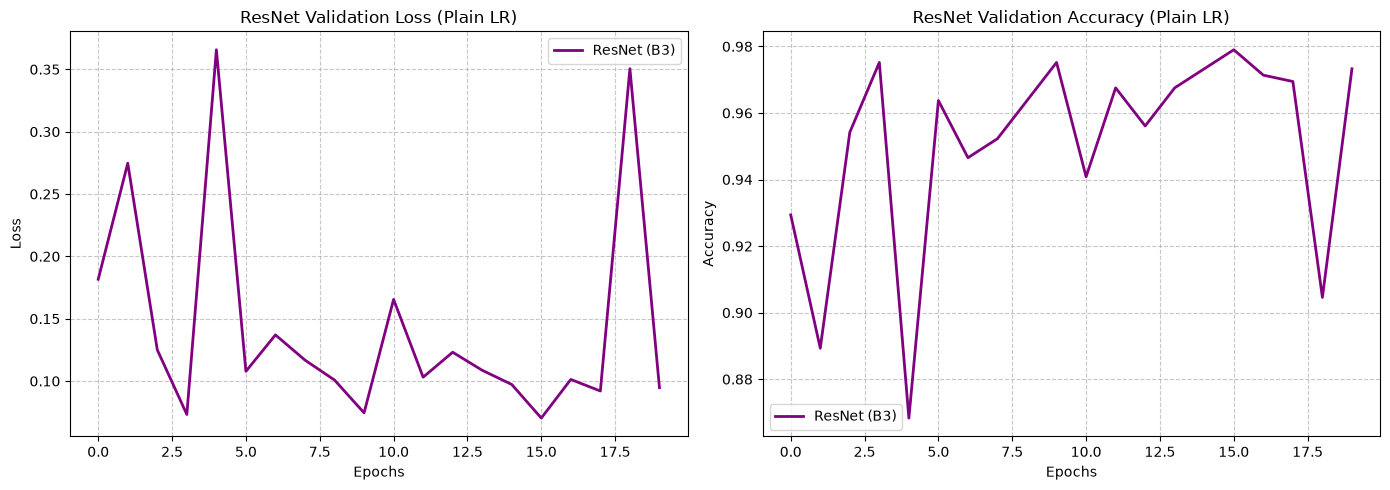


--- Final Test Set Evaluation & Metrics ---

Model: B1_AlexNet
  Accuracy    : 0.6250
  Precision   : 0.6250
  Sensitivity : 1.0000
  Specificity : 0.0000

--- Architecture Summary for B1_AlexNet ---

Model: B2_VGG
  Accuracy    : 0.8157
  Precision   : 0.7812
  Sensitivity : 0.9795
  Specificity : 0.5427

--- Architecture Summary for B2_VGG ---

Model: B3_ResNet
  Accuracy    : 0.8734
  Precision   : 0.8463
  Sensitivity : 0.9744
  Specificity : 0.7051

--- Architecture Summary for B3_ResNet ---


In [19]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchinfo import summary
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# --- 1. Plain Training Function (To check ResNet instability) ---
def train_model_plain(model, train_loader, val_loader, lr, epochs=20):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)  # Plain training, no scheduler, no clipping
    
    history = {'val_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                
                preds = (torch.sigmoid(outputs) > 0.5).float()
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        print(f"Epoch [{epoch+1}/{epochs}] - Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.4f}")
        
    return history

# --- 2. Train B3 ResNet using best batch size and best LR ---
print("--- Training B3 ResNet (Plain Training) ---")
train_loader_final, val_loader_final, test_loader_final, _, _ = load_and_preprocess_data(batch_size=best_bs_b2)
model_b3 = B3_ResNet().to(device)
b3_history = train_model_plain(model_b3, train_loader_final, val_loader_final, lr=best_lr_b1)

# --- 3. Plotting and Saving ResNet History ---
os.makedirs('images', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(b3_history['val_loss'], label='ResNet (B3)', color='purple', linewidth=2)
axes[1].plot(b3_history['val_acc'], label='ResNet (B3)', color='purple', linewidth=2)

axes[0].set_title('ResNet Validation Loss (Plain LR)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

axes[1].set_title('ResNet Validation Accuracy (Plain LR)')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
output_path = os.path.join('images', 'resnet_plain_comparison.png')
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Plot saved to {output_path}")
plt.show()

# --- 4. Evaluation Function ---
def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.round(torch.sigmoid(outputs))
            
            # Move targets and preds to CPU numpy arrays safely
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    # Sensitivity (Recall)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    
    # Specificity calculation from confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    else:
        specificity = 0.0
        
    return {
        'accuracy': acc,
        'precision': precision,
        'sensitivity': sensitivity,
        'specificity': specificity
    }

# --- 5. Evaluate All Three Final Models on Test Set & Compare Architecture Specs ---
models = {
    'B1_AlexNet': model_b1,
    'B2_VGG': model_b2,
    'B3_ResNet': model_b3
}

print("\n--- Final Test Set Evaluation & Metrics ---")
for name, model in models.items():
    metrics = evaluate_model(model, test_loader_final)
    print(f"\nModel: {name}")
    print(f"  Accuracy    : {metrics['accuracy']:.4f}")
    print(f"  Precision   : {metrics['precision']:.4f}")
    print(f"  Sensitivity : {metrics['sensitivity']:.4f}")
    print(f"  Specificity : {metrics['specificity']:.4f}")
    
    print(f"\n--- Architecture Summary for {name} ---")
    # Assumes input shape (Batch, 1, Height, Width) - adjust channels/size if needed (e.g., 64x64)
    summary(model, input_size=(best_bs_b2, 1, 64, 64), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# Stablized ResNet

--- Training B3 ResNet (Stable Training) ---
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Epoch [1/20] - Val Loss: 0.3038 - Val Acc: 0.9160
Epoch [2/20] - Val Loss: 0.2465 - Val Acc: 0.9237
Epoch [3/20] - Val Loss: 0.2213 - Val Acc: 0.9332
Epoch [4/20] - Val Loss: 0.1630 - Val Acc: 0.9485
Epoch [5/20] - Val Loss: 0.1498 - Val Acc: 0.9447
Epoch [6/20] - Val Loss: 0.1373 - Val Acc: 0.9504
Epoch [7/20] - Val Loss: 0.1426 - Val Acc: 0.9447
Epoch [8/20] - Val Loss: 0.1214 - Val Acc: 0.9580
Epoch [9/20] - Val Loss: 0.1538 - Val Acc: 0.9389
Epoch [10/20] - Val Loss: 0.1111 - Val Acc: 0.9580
Epoch [11/20] - Val Loss: 0.1758 - Val Acc: 0.9275
Epoch [12/20] - Val Loss: 0.1082 - Val Acc: 0.9676
Epoch [13/20] - Val Loss: 0.1001 - Val Acc: 0.9599
Epoch [14/20] - Val Loss: 0.0999 - Val Acc: 0.9637
Epoch [15/20] - Val Loss: 0.0947 - Val Acc: 0.9714
Epoch [16/20] - Val Loss: 0.0979 - Val Acc: 0.9656
Epoch [17/20] - Val Loss: 0.135

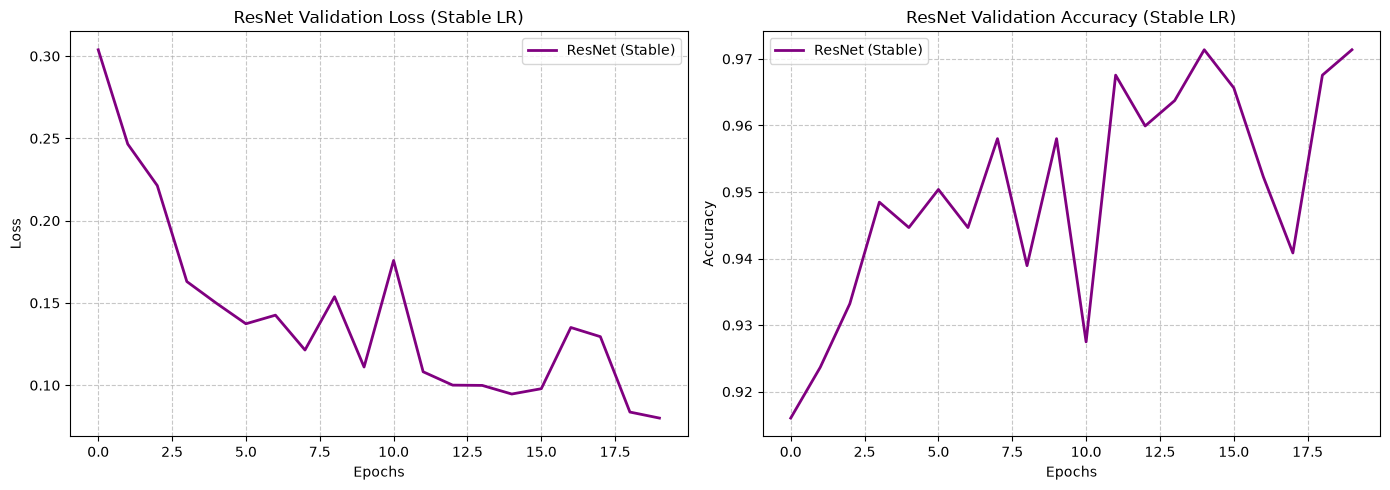


--- Final Test Set Evaluation & Metrics ---

Model: B1_AlexNet
  Accuracy    : 0.6250
  Precision   : 0.6250
  Sensitivity : 1.0000
  Specificity : 0.0000

--- Architecture Summary for B1_AlexNet ---

Model: B2_VGG
  Accuracy    : 0.8157
  Precision   : 0.7812
  Sensitivity : 0.9795
  Specificity : 0.5427

--- Architecture Summary for B2_VGG ---

Model: B3_ResNet
  Accuracy    : 0.8830
  Precision   : 0.8468
  Sensitivity : 0.9923
  Specificity : 0.7009

--- Architecture Summary for B3_ResNet ---


In [20]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchinfo import summary
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# --- 1. Stabilized Training Function for ResNet ---
def train_resnet_stable(model, train_loader, val_loader, lr, epochs=20):
    criterion = nn.BCEWithLogitsLoss()
    # Add weight decay and a dedicated stable learning rate for ResNet
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # Scheduler to lower LR automatically if validation loss plateaus
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
    
    history = {'val_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            
            # Gradient clipping to prevent sudden exploding gradient spikes
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
            
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                
                preds = (torch.sigmoid(outputs) > 0.5).float()
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        
        # Step the scheduler based on validation loss
        scheduler.step(epoch_val_loss)
        print(f"Epoch [{epoch+1}/{epochs}] - Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.4f}")
        
    return history

# --- 2. Train B3 ResNet using Stable Settings ---
print("--- Training B3 ResNet (Stable Training) ---")
train_loader_final, val_loader_final, test_loader_final, _, _ = load_and_preprocess_data(batch_size=best_bs_b2)
model_b3 = B3_ResNet().to(device)

# Using a safer, tuned learning rate for ResNet (e.g., 1e-4)
resnet_lr = 1e-4
b3_history = train_resnet_stable(model_b3, train_loader_final, val_loader_final, lr=resnet_lr)

# --- 3. Plotting and Saving Stabilized ResNet History ---
os.makedirs('images', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(b3_history['val_loss'], label='ResNet (Stable)', color='purple', linewidth=2)
axes[1].plot(b3_history['val_acc'], label='ResNet (Stable)', color='purple', linewidth=2)

axes[0].set_title('ResNet Validation Loss (Stable LR)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

axes[1].set_title('ResNet Validation Accuracy (Stable LR)')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
output_path = os.path.join('images', 'resnet_stable_comparison.png')
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Plot saved to {output_path}")
plt.show()

# --- 4. Evaluation Function ---
def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.round(torch.sigmoid(outputs))
            
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    else:
        specificity = 0.0
        
    return {
        'accuracy': acc,
        'precision': precision,
        'sensitivity': sensitivity,
        'specificity': specificity
    }

# --- 5. Evaluate All Three Models & Compare Metrics/Architectures ---
models = {
    'B1_AlexNet': model_b1,
    'B2_VGG': model_b2,
    'B3_ResNet': model_b3
}

print("\n--- Final Test Set Evaluation & Metrics ---")
for name, model in models.items():
    metrics = evaluate_model(model, test_loader_final)
    print(f"\nModel: {name}")
    print(f"  Accuracy    : {metrics['accuracy']:.4f}")
    print(f"  Precision   : {metrics['precision']:.4f}")
    print(f"  Sensitivity : {metrics['sensitivity']:.4f}")
    print(f"  Specificity : {metrics['specificity']:.4f}")
    
    print(f"\n--- Architecture Summary for {name} ---")
    summary(model, input_size=(best_bs_b2, 1, 64, 64), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# Explainable AI

In [23]:
print("--- AlexNet (model_b1) Layers ---")
for idx, layer in enumerate(model_b1.features):
    print(f"{idx}: {type(layer)}")

print("\n--- VGG (model_b2) Layers ---")
for idx, layer in enumerate(model_b2.features):
    print(f"{idx}: {type(layer)}")

--- AlexNet (model_b1) Layers ---
0: <class '__main__.ConvBlock'>
1: <class 'torch.nn.modules.pooling.MaxPool2d'>
2: <class '__main__.ConvBlock'>
3: <class 'torch.nn.modules.pooling.MaxPool2d'>
4: <class '__main__.ConvBlock'>
5: <class 'torch.nn.modules.pooling.MaxPool2d'>
6: <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>

--- VGG (model_b2) Layers ---
0: <class '__main__.ConvBlock'>
1: <class '__main__.ConvBlock'>
2: <class 'torch.nn.modules.pooling.MaxPool2d'>
3: <class '__main__.ConvBlock'>
4: <class '__main__.ConvBlock'>
5: <class 'torch.nn.modules.pooling.MaxPool2d'>
6: <class '__main__.ConvBlock'>
7: <class '__main__.ConvBlock'>
8: <class 'torch.nn.modules.pooling.MaxPool2d'>
9: <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>


--- Generating Smooth Grad-CAM Visualizations ---


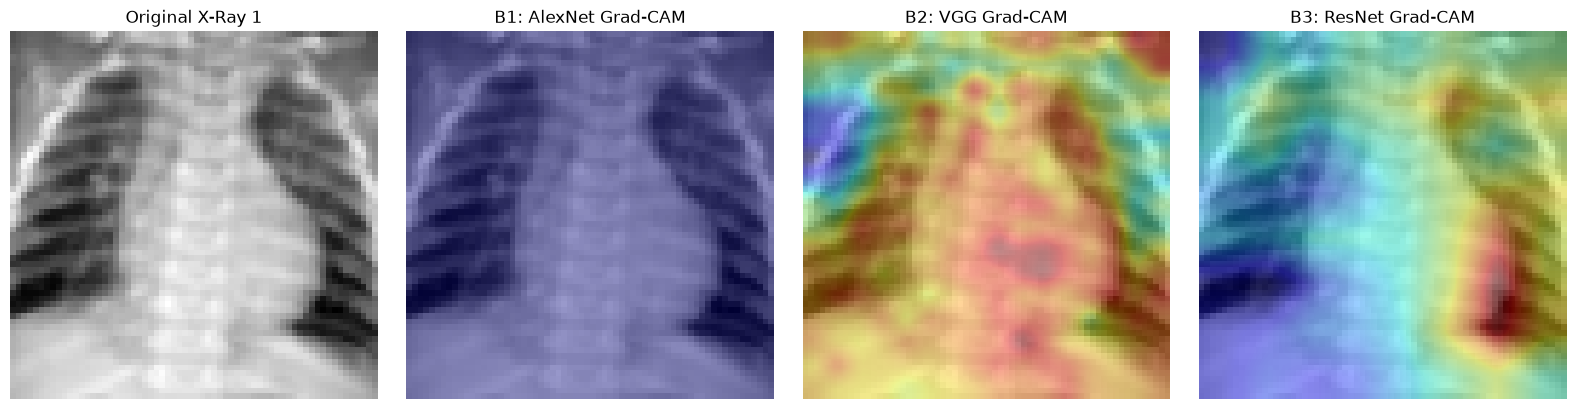

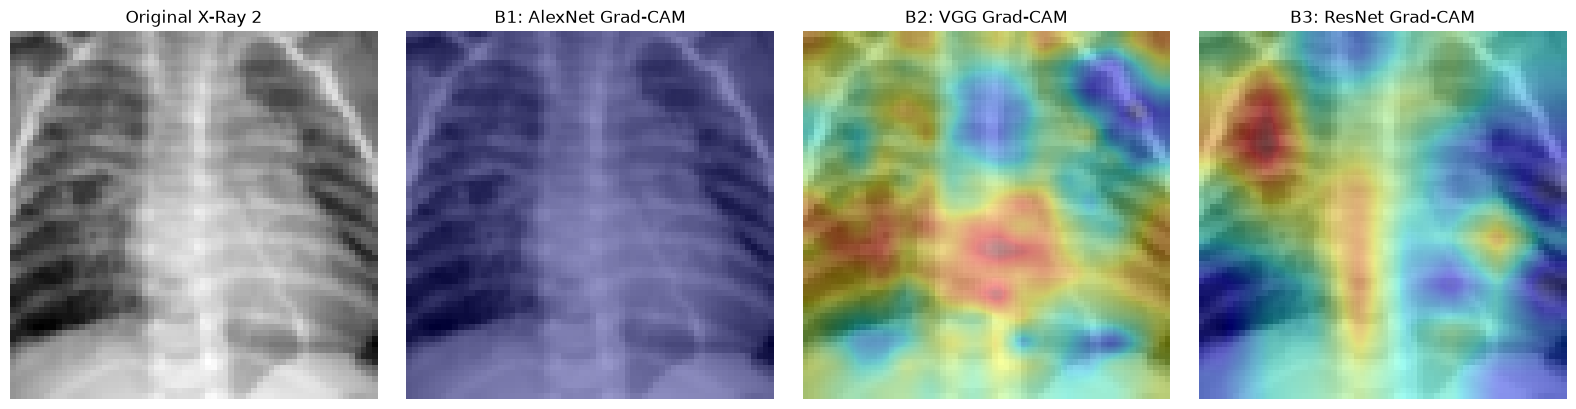

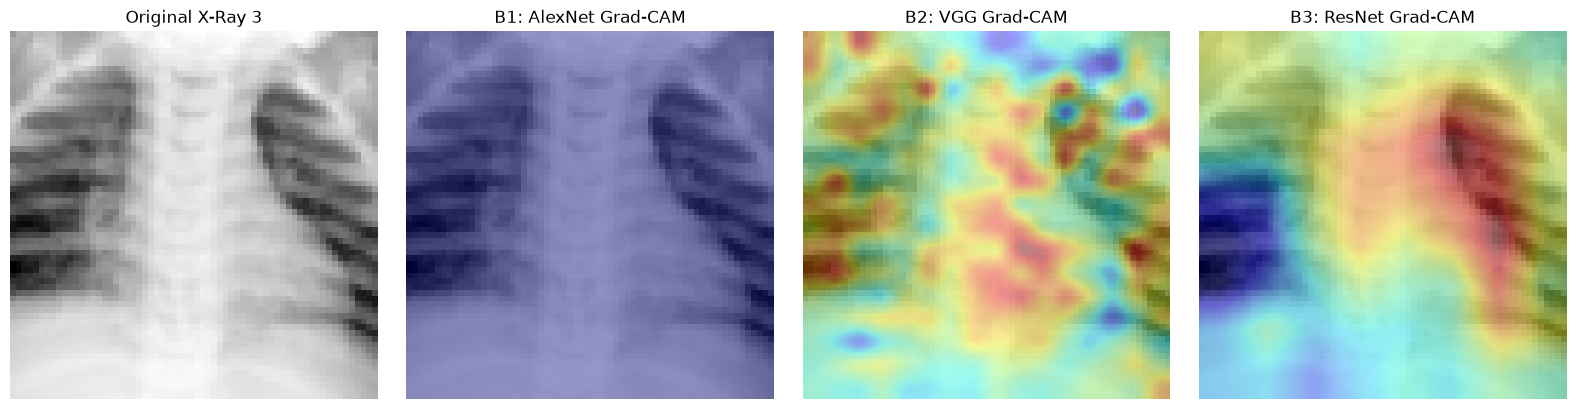

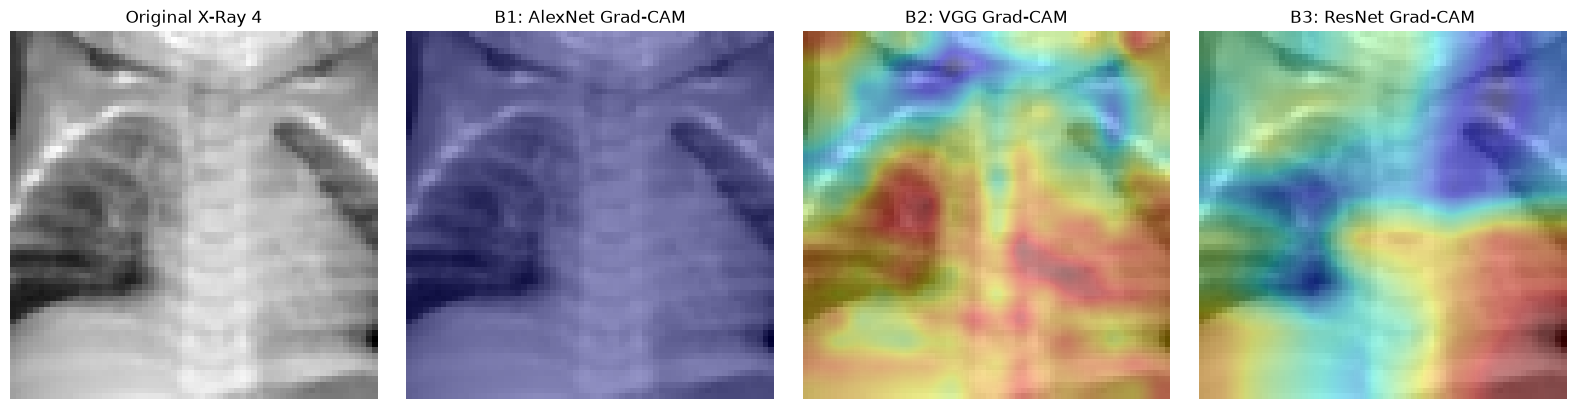

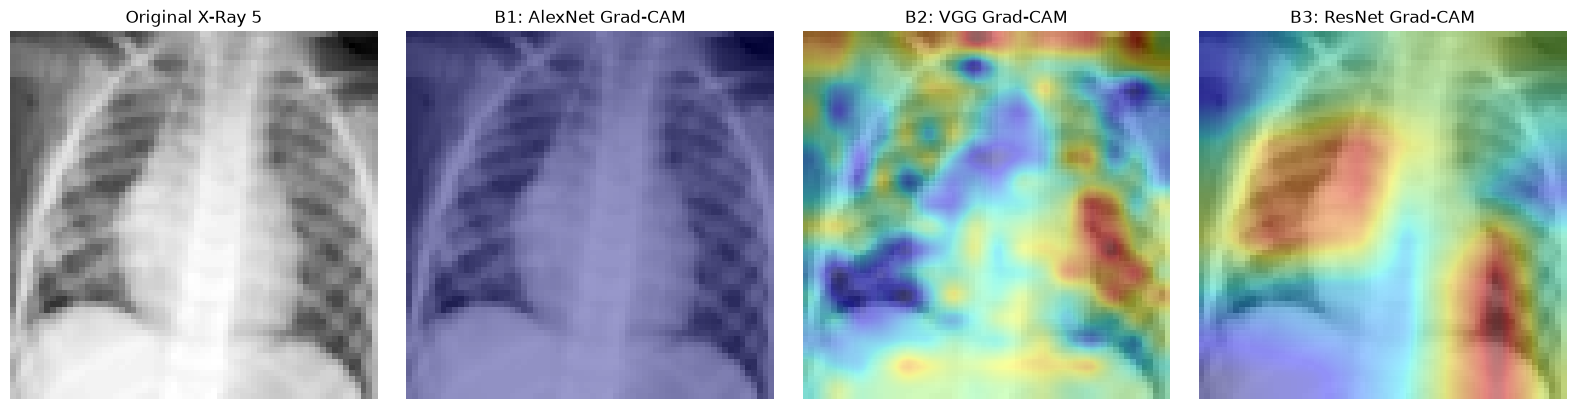

Smooth Grad-CAM images successfully generated and saved to 'images/gradcam/'!
ROC Curve plot saved successfully to images/roc_curve_comparison.png


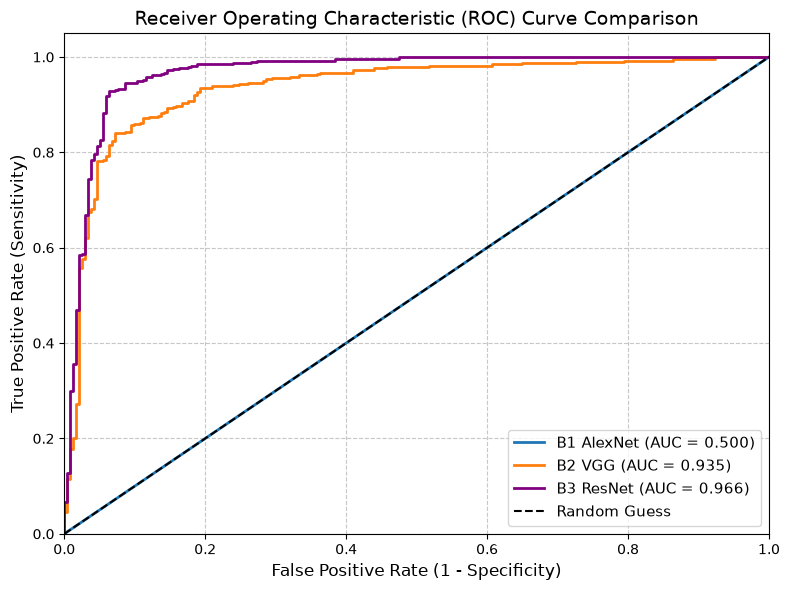

In [27]:
import os
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from captum.attr import LayerGradCam

# 1. Select 5 random pneumonia positive samples (target == 1)
pneumonia_indices = torch.where(y_test_t == 1)[0]
sample_indices = pneumonia_indices[torch.randperm(len(pneumonia_indices))[:5]]
sample_images = X_test_t[sample_indices].to(device)

# Ensure models are in evaluation mode
model_b1.eval()
model_b2.eval()
model_b3.eval()

# 2. Initialize Grad-CAM targeting the inner conv layer of the final ConvBlock / ResNet layer
# Based on your layer printouts:
# AlexNet last ConvBlock is at features[4]
# VGG last ConvBlock is at features[6]
# ResNet last layer is layer3.conv2 (or check if your ResNet uses standard blocks, we can target layer3)

# Helper to find the conv layer inside your custom ConvBlock if needed, 
# or directly access if it's named 'conv' or similar inside ConvBlock:
def get_conv_from_block(block):
    # Search for any Conv2d module inside the custom ConvBlock
    for m in block.modules():
        if isinstance(m, torch.nn.Conv2d):
            return m
    raise ValueError("No Conv2d found in this block")

cam_b1 = LayerGradCam(model_b1, get_conv_from_block(model_b1.features[4]))
cam_b2 = LayerGradCam(model_b2, get_conv_from_block(model_b2.features[6]))
cam_b3 = LayerGradCam(model_b3, model_b3.layer3.conv2) # Adjust to model_b3.layer4[1].conv2 if ResNet-18/50 style

os.makedirs('images/gradcam', exist_ok=True)

print("--- Generating Smooth Grad-CAM Visualizations ---")
for i in range(5):
    img = sample_images[i:i+1] # Shape: (1, 1, H, W)
    
    # Generate attributions
    attr_b1 = cam_b1.attribute(img, target=None)
    attr_b2 = cam_b2.attribute(img, target=None)
    attr_b3 = cam_b3.attribute(img, target=None)
    
    # Upsample attributions smoothly to original image dimensions using torch.nn.functional.interpolate
    target_size = img.shape[2:] # (H, W)
    attr_b1_up = F.interpolate(attr_b1, size=target_size, mode='bilinear', align_corners=False)
    attr_b2_up = F.interpolate(attr_b2, size=target_size, mode='bilinear', align_corners=False)
    attr_b3_up = F.interpolate(attr_b3, size=target_size, mode='bilinear', align_corners=False)
    
    orig_img_np = img.squeeze(0).cpu().permute(1, 2, 0).numpy().squeeze()
    
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    
    # Original Image
    axes[0].imshow(orig_img_np, cmap='gray')
    axes[0].set_title(f"Original X-Ray {i+1}")
    axes[0].axis('off')
    
    # Helper to plot smooth heatmap overlay
    def plot_smooth_heatmap(ax, bg_img, attr_tensor, title):
        ax.imshow(bg_img, cmap='gray')
        hm = attr_tensor.squeeze().detach().cpu().numpy()
        if hm.max() > hm.min():
            hm = (hm - hm.min()) / (hm.max() - hm.min()) # Normalize between 0 and 1
        ax.imshow(hm, cmap='jet', alpha=0.4, interpolation='bilinear')
        ax.set_title(title)
        ax.axis('off')

    plot_smooth_heatmap(axes[1], orig_img_np, attr_b1_up, "B1: AlexNet Grad-CAM")
    plot_smooth_heatmap(axes[2], orig_img_np, attr_b2_up, "B2: VGG Grad-CAM")
    plot_smooth_heatmap(axes[3], orig_img_np, attr_b3_up, "B3: ResNet Grad-CAM")
    
    plt.tight_layout()
    save_path = os.path.join('images/gradcam', f'sample_{i+1}_gradcam.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

print("Smooth Grad-CAM images successfully generated and saved to 'images/gradcam/'!")


# --- 3. ROC Curve Generation ---
def get_probabilities(model, loader):
    model.eval()
    y_true, y_probs = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.sigmoid(outputs)
            y_true.extend(targets.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())
    return np.array(y_true), np.array(y_probs)

y_true_b1, y_prob_b1 = get_probabilities(model_b1, test_loader_final)
y_true_b2, y_prob_b2 = get_probabilities(model_b2, test_loader_final)
y_true_b3, y_prob_b3 = get_probabilities(model_b3, test_loader_final)

fpr_b1, tpr_b1, _ = roc_curve(y_true_b1, y_prob_b1)
roc_auc_b1 = auc(fpr_b1, tpr_b1)

fpr_b2, tpr_b2, _ = roc_curve(y_true_b2, y_prob_b2)
roc_auc_b2 = auc(fpr_b2, tpr_b2)

fpr_b3, tpr_b3, _ = roc_curve(y_true_b3, y_prob_b3)
roc_auc_b3 = auc(fpr_b3, tpr_b3)

plt.figure(figsize=(8, 6))
plt.plot(fpr_b1, tpr_b1, label=f'B1 AlexNet (AUC = {roc_auc_b1:.3f})', linewidth=2)
plt.plot(fpr_b2, tpr_b2, label=f'B2 VGG (AUC = {roc_auc_b2:.3f})', linewidth=2)
plt.plot(fpr_b3, tpr_b3, label=f'B3 ResNet (AUC = {roc_auc_b3:.3f})', linewidth=2, color='purple')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Guess')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
roc_output_path = os.path.join('images', 'roc_curve_comparison.png')
plt.savefig(roc_output_path, dpi=300, bbox_inches='tight')
print(f"ROC Curve plot saved successfully to {roc_output_path}")
plt.show()

## Error Analysis using Grad CAM

Total False Negatives found: 3
Total False Positives found: 70

--- Generating Grad-CAM for False_Negative (3 samples) ---


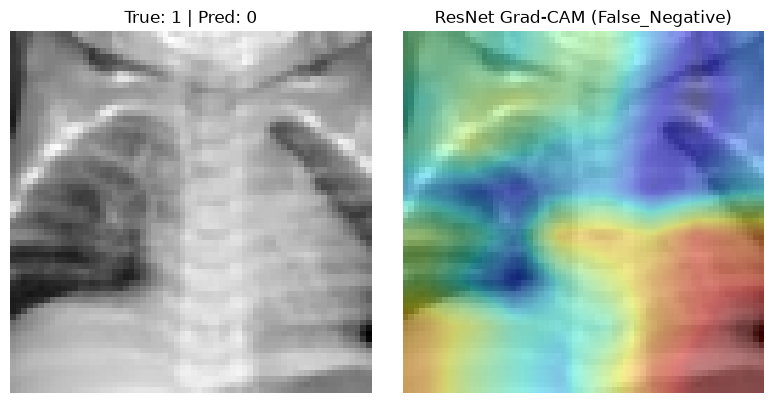

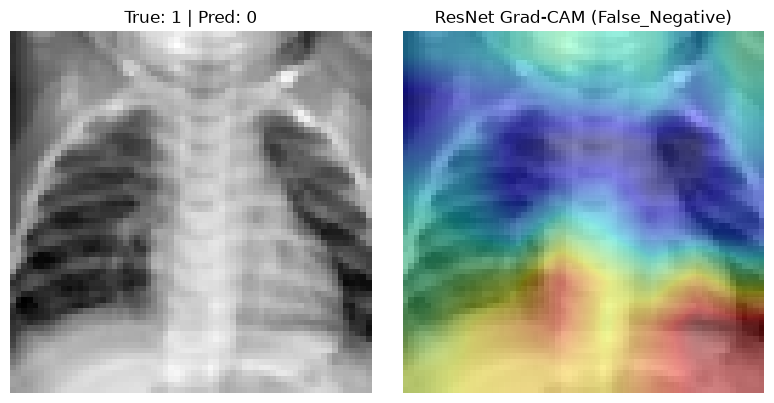

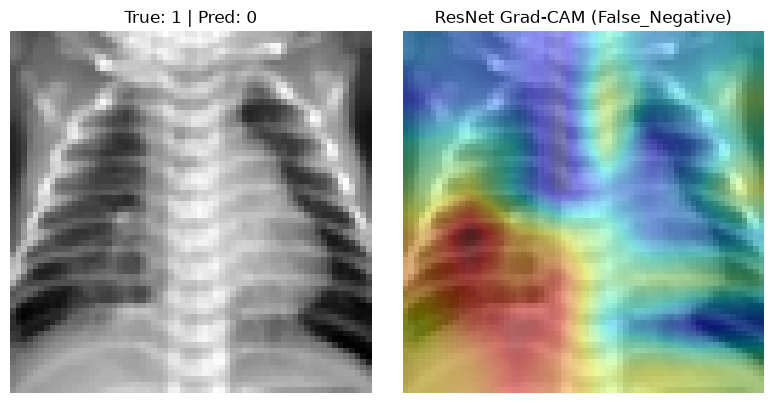


--- Generating Grad-CAM for False_Positive (5 samples) ---


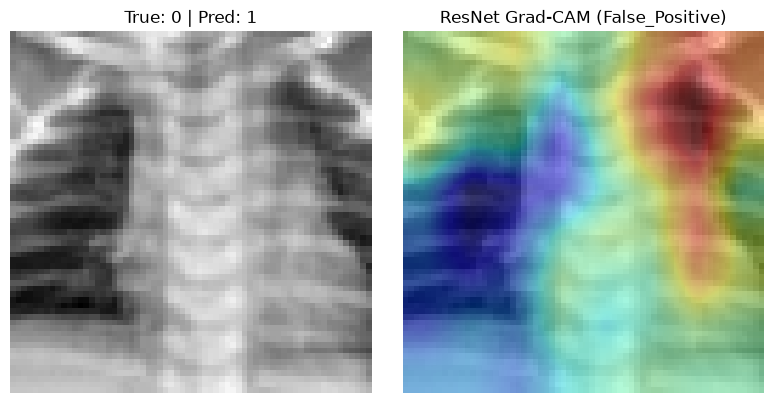

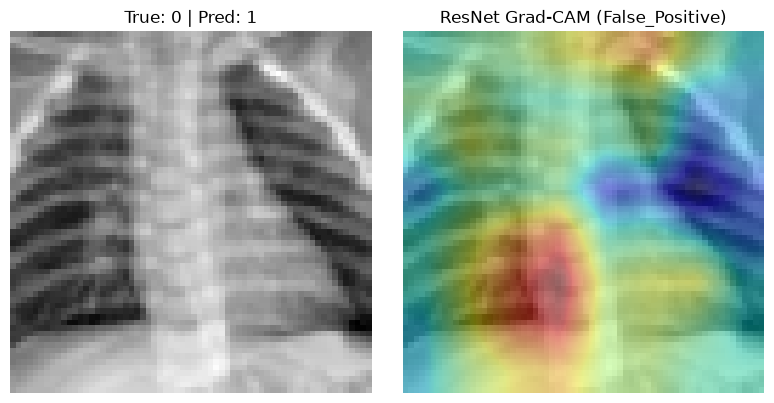

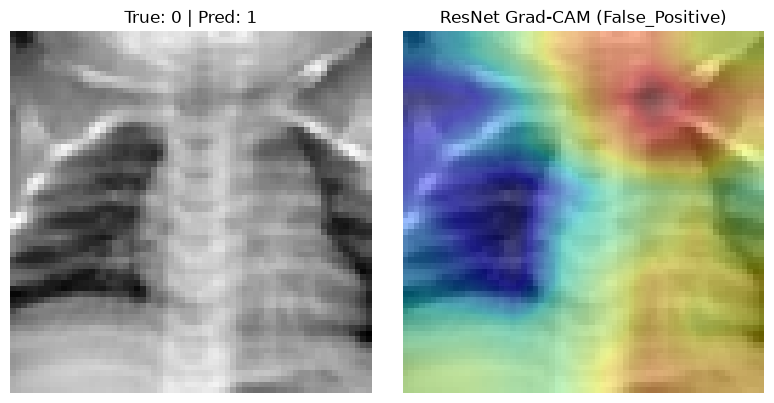

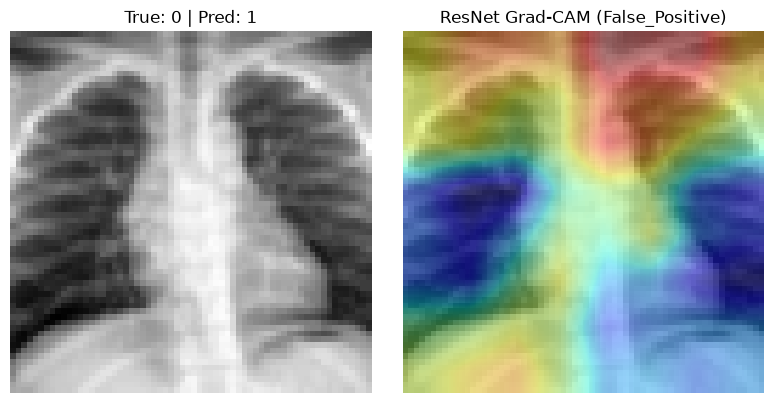

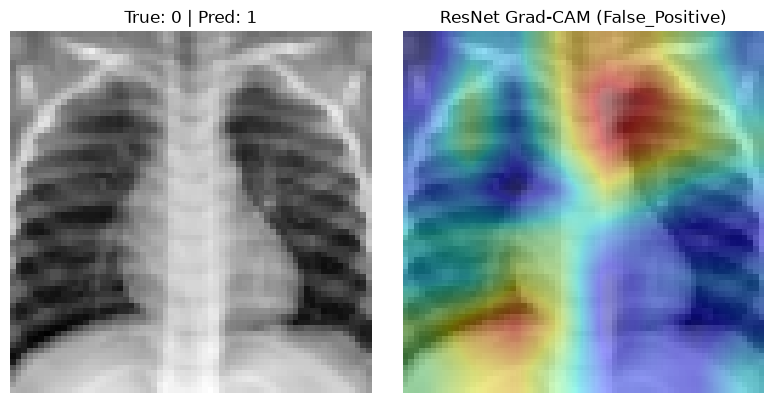

In [28]:
import os
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam

# Ensure output directory exists
os.makedirs('images/error_analysis', exist_ok=True)

# 1. Get predictions for the entire test set using our best model (ResNet - B3)
model_b3.eval()
all_preds, all_targets, all_images = [], [], []

with torch.no_grad():
    for inputs, targets in test_loader_final:
        inputs = inputs.to(device)
        outputs = model_b3(inputs)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())
        all_images.append(inputs.cpu())

all_preds = np.array(all_preds).squeeze()
all_targets = np.array(all_targets).squeeze()
all_images = torch.cat(all_images, dim=0)

# 2. Identify False Negatives and False Positives indices
fn_indices = np.where((all_preds == 0) & (all_targets == 1))[0] # Missed Pneumonia
fp_indices = np.where((all_preds == 1) & (all_targets == 0))[0] # False Alarm (Normal flagged as Pneumonia)

print(f"Total False Negatives found: {len(fn_indices)}")
print(f"Total False Positives found: {len(fp_indices)}")

# 3. Initialize Grad-CAM for ResNet (model_b3)
cam_b3 = LayerGradCam(model_b3, model_b3.layer3.conv2)

def generate_error_gradcam(indices, error_type_name):
    if len(indices) == 0:
        print(f"No {error_type_name} samples found to analyze.")
        return
    
    # Pick up to 5 samples
    selected_indices = indices[:5]
    error_images = all_images[selected_indices].to(device)
    
    print(f"\n--- Generating Grad-CAM for {error_type_name} ({len(selected_indices)} samples) ---")
    
    for i, idx in enumerate(selected_indices):
        img = error_images[i:i+1] # Shape: (1, 1, H, W)
        
        # Generate attributions
        attr = cam_b3.attribute(img, target=None)
        
        # Upsample smoothly using bilinear interpolation
        attr_up = F.interpolate(attr, size=img.shape[2:], mode='bilinear', align_corners=False)
        
        orig_img_np = img.squeeze(0).cpu().permute(1, 2, 0).numpy().squeeze()
        hm = attr_up.squeeze().detach().cpu().numpy()
        
        if hm.max() > hm.min():
            hm = (hm - hm.min()) / (hm.max() - hm.min())
            
        # Plotting side-by-side: Original vs Grad-CAM Overlay
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        
        # Original Image
        axes[0].imshow(orig_img_np, cmap='gray')
        axes[0].set_title(f"True: {int(all_targets[idx])} | Pred: {int(all_preds[idx])}")
        axes[0].axis('off')
        
        # Grad-CAM Heatmap Overlay
        axes[1].imshow(orig_img_np, cmap='gray')
        axes[1].imshow(hm, cmap='jet', alpha=0.4, interpolation='bilinear')
        axes[1].set_title(f"ResNet Grad-CAM ({error_type_name})")
        axes[1].axis('off')
        
        plt.tight_layout()
        save_path = os.path.join('images/error_analysis', f'{error_type_name}_sample_{i+1}.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

# Run error analysis generation for both categories
generate_error_gradcam(fn_indices, "False_Negative")
generate_error_gradcam(fp_indices, "False_Positive")